# 01 · Data Cleaning & Exploratory Data Analysis (EDA)
**Project:** Superstore Sales Analysis · **Stage 2 of 5** (Python)

**Goals of this notebook**
1. Load the raw Kaggle *Sample - Superstore* file and inspect its quality.
2. Clean it (types, text, postal codes, duplicates) and add analysis-ready features.
3. Explore sales, profit, discounts, geography, customers and products to extract insights.
4. Export a clean dataset to `data/clean/` and charts to `images/` (used later by SQL, Power BI and the README).

## 0. Setup

In [1]:
import warnings; warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 13, "axes.spines.top": False, "axes.spines.right": False})
BLUE, ORANGE, GREEN, RED = "#1f77b4", "#ff9f1c", "#2a9d8f", "#e5484d"
pd.set_option("display.max_columns", 50); pd.set_option("display.float_format", "{:,.2f}".format)

IMG   = Path("../images");      IMG.mkdir(exist_ok=True)
CLEAN = Path("../data/clean");  CLEAN.mkdir(parents=True, exist_ok=True)
money = mtick.FuncFormatter(lambda x, _: f"${x/1e3:,.0f}K" if abs(x) >= 1e3 else f"${x:,.0f}")

def save(name):
    plt.tight_layout(); plt.savefig(IMG / f"{name}.png", bbox_inches="tight"); plt.show()

## 1. Load the raw data
The Kaggle file is encoded in **Windows-1252** (not UTF-8), so the encoding must be set explicitly.

In [2]:
CANDIDATES = [Path("../data/raw/Sample - Superstore.csv"), Path("../data/Sample - Superstore.csv"), Path("Sample - Superstore.csv")]
RAW_PATH = next((p for p in CANDIDATES if p.exists()), None)
if RAW_PATH is None:
    raise FileNotFoundError("Put 'Sample - Superstore.csv' in data/raw/ (or edit CANDIDATES above).")

df = pd.read_csv(RAW_PATH, encoding="cp1252")
print(f"Loaded {RAW_PATH}  ->  {df.shape[0]:,} rows × {df.shape[1]} columns")
df.head()

Loaded ..\data\raw\Sample - Superstore.csv  ->  9,994 rows × 21 columns


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.96,2,0.00,41.91
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.94,3,0.00,219.58
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.62,2,0.00,6.87
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.58,5,0.45,-383.03
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.37,2,0.20,2.52


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   str    
 2   Order Date     9994 non-null   str    
 3   Ship Date      9994 non-null   str    
 4   Ship Mode      9994 non-null   str    
 5   Customer ID    9994 non-null   str    
 6   Customer Name  9994 non-null   str    
 7   Segment        9994 non-null   str    
 8   Country        9994 non-null   str    
 9   City           9994 non-null   str    
 10  State          9994 non-null   str    
 11  Postal Code    9994 non-null   int64  
 12  Region         9994 non-null   str    
 13  Product ID     9994 non-null   str    
 14  Category       9994 non-null   str    
 15  Sub-Category   9994 non-null   str    
 16  Product Name   9994 non-null   str    
 17  Sales          9994 non-null   float64
 18  Quantity       9994

## 2. Data quality checks

In [4]:
# 2.1 Missing values
print("Total missing values:", int(df.isna().sum().sum()))

# 2.2 Duplicates (ignoring the unique Row ID)
dup_cols = [c for c in df.columns if c != "Row ID"]
dups = df[df.duplicated(subset=dup_cols, keep=False)]
print(f"\nRows that are exact duplicates (excluding Row ID): {len(dups)}")
display(dups[["Row ID", "Order ID", "Product ID", "Sales", "Quantity", "Profit"]])

# 2.3 Leading / trailing whitespace in text columns
text_cols = df.select_dtypes(include=["object", "string"]).columns
ws = {c: int((df[c] != df[c].str.strip()).sum()) for c in text_cols}
print("\nCells with extra whitespace:", {c: n for c, n in ws.items() if n} or "none")

# 2.4 Postal codes lost their leading zero when stored as numbers
pc_len = df["Postal Code"].astype(str).str.len().value_counts().sort_index()
print("\nPostal Code length distribution:", pc_len.to_dict(), "(US ZIPs must have 5 digits)")

# 2.5 Logical checks
od = pd.to_datetime(df["Order Date"], format="%m/%d/%Y"); sd = pd.to_datetime(df["Ship Date"], format="%m/%d/%Y")
print("\nShip date before order date:", int((sd < od).sum()))
print("Non-positive sales / quantity:", int((df.Sales <= 0).sum()), "/", int((df.Quantity <= 0).sum()))
print("Discount range:", df.Discount.min(), "→", df.Discount.max())

# 2.6 Product IDs that map to more than one product name
multi = df.groupby("Product ID")["Product Name"].nunique()
print("\nProduct IDs with >1 product name:", int((multi > 1).sum()))

Total missing values: 0

Rows that are exact duplicates (excluding Row ID): 2


,Row ID,Order ID,Product ID,Sales,Quantity,Profit
3405,3406,US-2014-150119,FUR-CH-10002965,281.37,2,-12.06
3406,3407,US-2014-150119,FUR-CH-10002965,281.37,2,-12.06



Cells with extra whitespace: {'Product Name': 16}

Postal Code length distribution: {4: 449, 5: 9545} (US ZIPs must have 5 digits)

Ship date before order date: 0
Non-positive sales / quantity: 0 / 0
Discount range: 0.0 → 0.8

Product IDs with >1 product name: 32


**Findings & decisions**

| Issue | Finding | Decision |
|---|---|---|
| Missing values | None | – |
| Duplicates | 1 identical order line (Row ID 3406 / 3407) | **Flag, don't drop** – it can be a genuine repeat line; impact is tiny (-\$12 profit) and keeping it keeps SQL / Power BI at 9,994 rows |
| Whitespace | Extra spaces in some text cells | Strip |
| Postal Code | 449 codes have 4 digits (leading zero lost, e.g. New England) | Convert to text and pad to 5 digits |
| Dates | Stored as text `m/d/yyyy` | Parse to `datetime` |
| Product ID → name | 32 product IDs have several names | Keep as is; **analyse products by Product ID**, and be careful when grouping by name |

## 3. Cleaning

In [5]:
clean = df.copy()

# text: trim whitespace
for c in text_cols:
    clean[c] = clean[c].str.strip()

# column names: Snake_Case (matches the SQL Server table)
clean.columns = [c.replace(" ", "_").replace("-", "_") for c in clean.columns]

# dates
clean["Order_Date"] = pd.to_datetime(clean["Order_Date"], format="%m/%d/%Y")
clean["Ship_Date"]  = pd.to_datetime(clean["Ship_Date"],  format="%m/%d/%Y")

# postal code as 5-character text
clean["Postal_Code"] = clean["Postal_Code"].astype(str).str.zfill(5)

# flag (not drop) the duplicated line
clean["Is_Duplicate_Line"] = clean.duplicated(subset=[c for c in clean.columns if c != "Row_ID"], keep="first")

print("Duplicate lines flagged:", int(clean.Is_Duplicate_Line.sum()))
print("All postal codes have 5 digits:", bool((clean.Postal_Code.str.len() == 5).all()))

Duplicate lines flagged: 1
All postal codes have 5 digits: True


## 4. Feature engineering

In [6]:
clean["Order_Year"]      = clean.Order_Date.dt.year
clean["Order_Month"]     = clean.Order_Date.dt.month
clean["Order_Quarter"]   = "Q" + clean.Order_Date.dt.quarter.astype(str)
clean["Order_YearMonth"] = clean.Order_Date.dt.to_period("M").astype(str)
clean["Order_Weekday"]   = clean.Order_Date.dt.day_name()
clean["Ship_Days"]       = (clean.Ship_Date - clean.Order_Date).dt.days
clean["Profit_Margin"]   = (clean.Profit / clean.Sales).round(4)
clean["Is_Loss"]         = clean.Profit < 0

bins   = [-0.001, 0, 0.1, 0.2, 0.4, 0.6, 1.0]
labels = ["No discount", "1-10%", "11-20%", "21-40%", "41-60%", "61%+"]
clean["Discount_Band"] = pd.cut(clean.Discount, bins=bins, labels=labels)

# ---- validation ----
assert clean.Row_ID.is_unique
assert (clean.Ship_Date >= clean.Order_Date).all()
assert clean.isna().sum().sum() == 0
assert (clean.Sales > 0).all()
print("All validation checks passed ✔")
clean.head(3).T

All validation checks passed ✔


,0,1,2
Row_ID,1,2,3
Order_ID,CA-2016-152156,CA-2016-152156,CA-2016-138688
Order_Date,2016-11-08 00:00:00,2016-11-08 00:00:00,2016-06-12 00:00:00
Ship_Date,2016-11-11 00:00:00,2016-11-11 00:00:00,2016-06-16 00:00:00
Ship_Mode,Second Class,Second Class,Second Class
Customer_ID,CG-12520,CG-12520,DV-13045
Customer_Name,Claire Gute,Claire Gute,Darrin Van Huff
Segment,Consumer,Consumer,Corporate
Country,United States,United States,United States
City,Henderson,Henderson,Los Angeles


## 5. Exploratory analysis

### 5.1 Overview

In [7]:
kpi = {
    "Order lines":   len(clean),
    "Orders":        clean.Order_ID.nunique(),
    "Customers":     clean.Customer_ID.nunique(),
    "Products":      clean.Product_ID.nunique(),
    "Period":        f"{clean.Order_Date.min():%Y-%m-%d} → {clean.Order_Date.max():%Y-%m-%d}",
    "Total sales":   f"${clean.Sales.sum():,.0f}",
    "Total profit":  f"${clean.Profit.sum():,.0f}",
    "Profit margin": f"{clean.Profit.sum() / clean.Sales.sum():.1%}",
    "Loss-making lines": f"{clean.Is_Loss.mean():.1%}",
}
display(pd.Series(kpi, name="Superstore at a glance").to_frame())
clean[["Sales", "Quantity", "Discount", "Profit", "Profit_Margin", "Ship_Days"]].describe().round(2)

,Superstore at a glance
Order lines,9994
Orders,5009
Customers,793
Products,1862
Period,2014-01-03 → 2017-12-30
Total sales,"$2,297,201"
Total profit,"$286,397"
Profit margin,12.5%
Loss-making lines,18.7%


,Sales,Quantity,Discount,Profit,Profit_Margin,Ship_Days
count,"9,994.00","9,994.00","9,994.00","9,994.00","9,994.00","9,994.00"
mean,229.86,3.79,0.16,28.66,0.12,3.96
std,623.25,2.23,0.21,234.26,0.47,1.75
min,0.44,1.00,0.00,"-6,599.98",-2.75,0.00
25%,17.28,2.00,0.00,1.73,0.08,3.00
50%,54.49,3.00,0.20,8.67,0.27,4.00
75%,209.94,5.00,0.20,29.36,0.36,5.00
max,"22,638.48",14.00,0.80,"8,399.98",0.50,7.00


### 5.2 Distributions

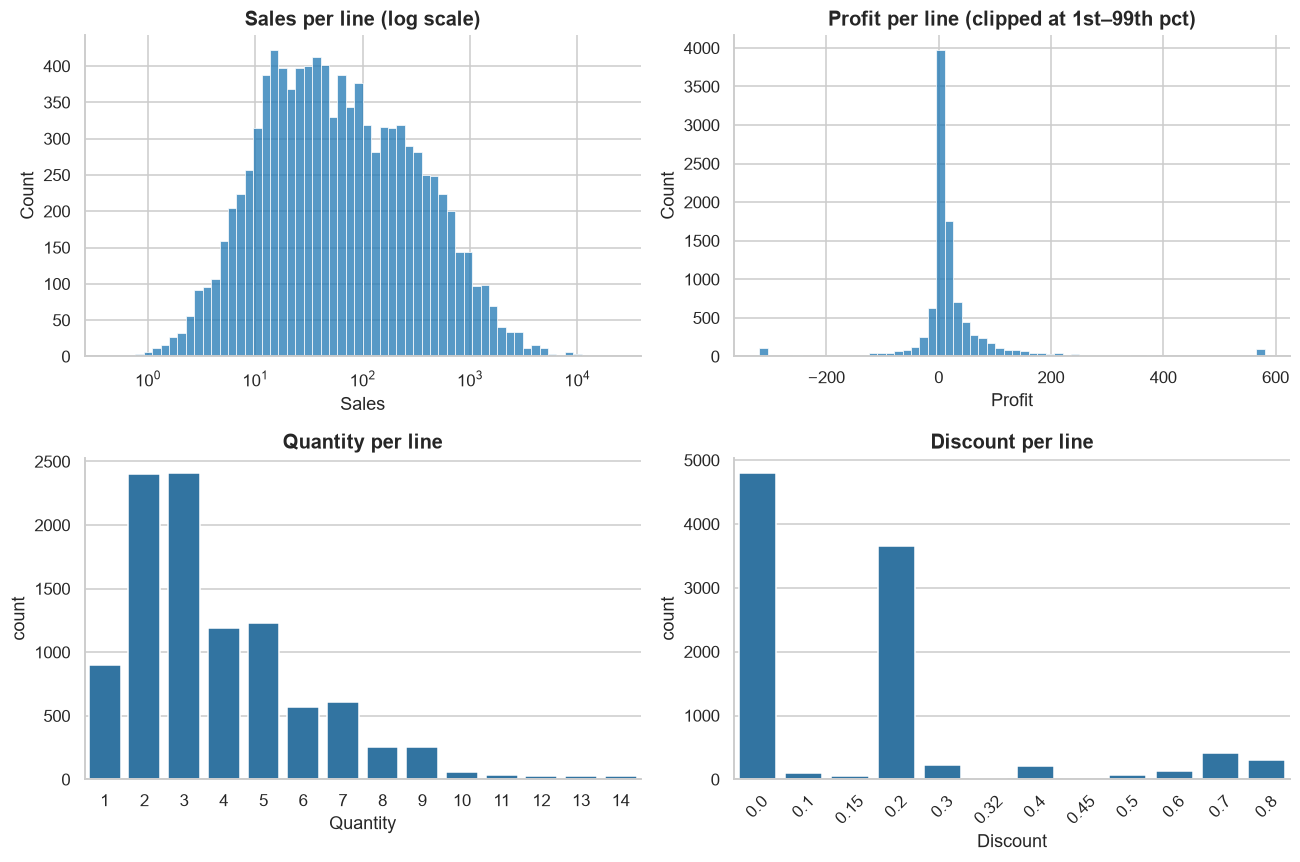

In [8]:
fig, ax = plt.subplots(2, 2, figsize=(12, 8))
sns.histplot(clean.Sales, bins=60, log_scale=True, ax=ax[0, 0], color=BLUE);  ax[0, 0].set_title("Sales per line (log scale)")
p1, p99 = clean.Profit.quantile([.01, .99])
sns.histplot(clean.Profit.clip(p1, p99), bins=60, ax=ax[0, 1], color=BLUE);   ax[0, 1].set_title("Profit per line (clipped at 1st–99th pct)")
sns.countplot(data=clean, x="Quantity", ax=ax[1, 0], color=BLUE);              ax[1, 0].set_title("Quantity per line")
sns.countplot(data=clean, x="Discount", ax=ax[1, 1], color=BLUE);              ax[1, 1].set_title("Discount per line")
ax[1, 1].tick_params(axis="x", rotation=45)
save("01_distributions")

Sales and profit are **heavily right-skewed** with a long tail of large orders and big losses, so averages are dominated by a few lines – medians and totals by group are more reliable.

### 5.3 Customer & order mix

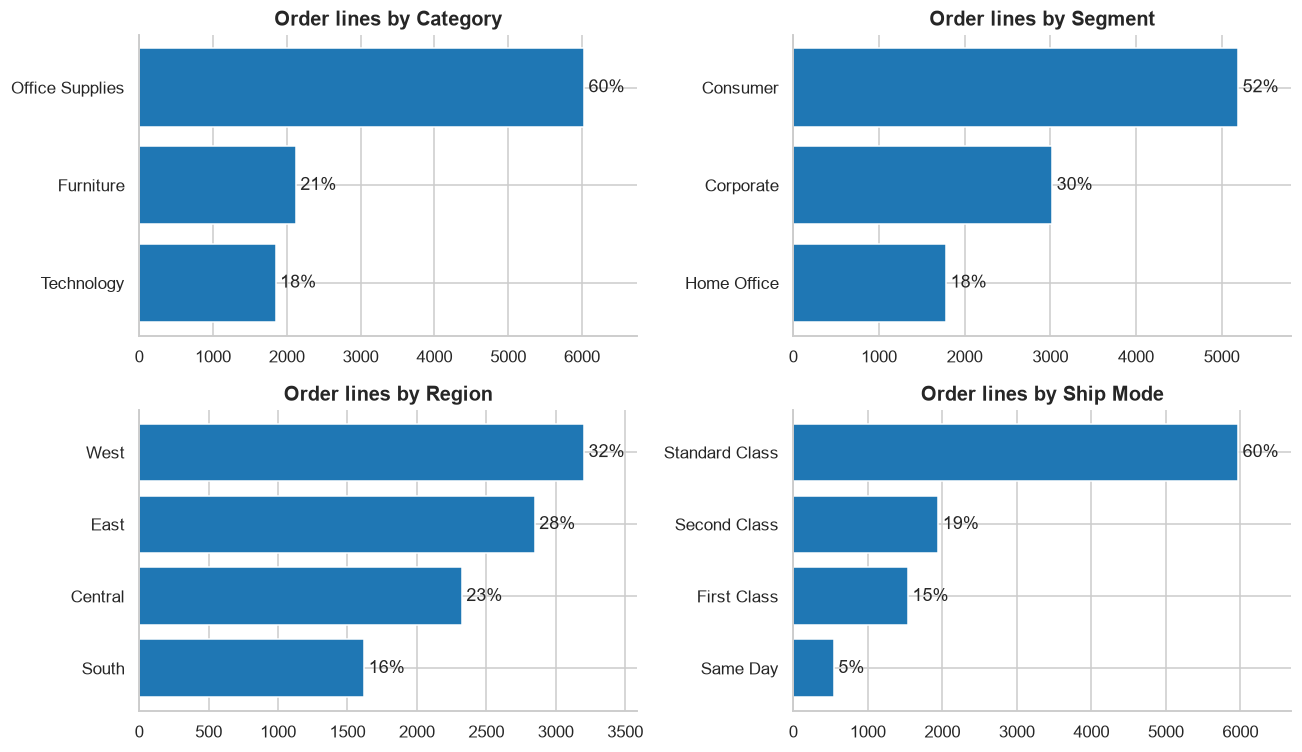

In [9]:
fig, ax = plt.subplots(2, 2, figsize=(12, 7))
for a, col in zip(ax.flat, ["Category", "Segment", "Region", "Ship_Mode"]):
    vc = clean[col].value_counts()
    bars = a.barh(vc.index[::-1], vc.values[::-1], color=BLUE)
    a.bar_label(bars, labels=[f"{v / len(clean):.0%}" for v in vc.values[::-1]], padding=3)
    a.set_title(f"Order lines by {col.replace('_', ' ')}"); a.margins(x=.12)
save("02_order_mix")

### 5.4 Trends over time

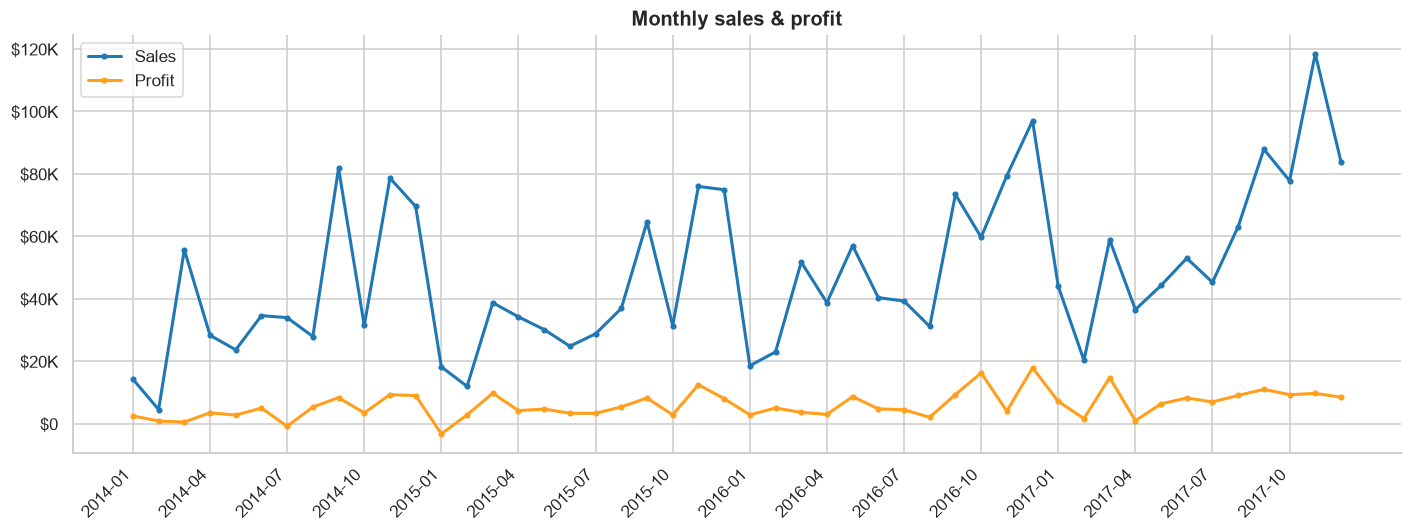

,Sales,Profit,Orders,Customers,Margin_%,Sales_YoY_%,Profit_YoY_%
Order_Year,,,,,,,
2014,"484,247.50","49,544.00",969,595,10.20,NaN,NaN
2015,"470,532.50","61,618.60",1038,573,13.10,-2.80,24.40
2016,"609,205.60","81,795.20",1315,638,13.40,29.50,32.70
2017,"733,215.30","93,439.30",1687,693,12.70,20.40,14.20


In [10]:
monthly = clean.groupby("Order_YearMonth")[["Sales", "Profit"]].sum()
fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(monthly.index, monthly.Sales, color=BLUE, lw=2, marker="o", ms=3, label="Sales")
ax.plot(monthly.index, monthly.Profit, color=ORANGE, lw=2, marker="o", ms=3, label="Profit")
ax.yaxis.set_major_formatter(money); ax.set_xticks(range(0, len(monthly), 3)); ax.set_xticklabels(monthly.index[::3], rotation=45, ha="right")
ax.set_title("Monthly sales & profit"); ax.legend()
save("03_monthly_trend")

yearly = clean.groupby("Order_Year").agg(Sales=("Sales", "sum"), Profit=("Profit", "sum"),
                                         Orders=("Order_ID", "nunique"), Customers=("Customer_ID", "nunique"))
yearly["Margin_%"] = yearly.Profit / yearly.Sales * 100
yearly["Sales_YoY_%"] = yearly.Sales.pct_change() * 100
yearly["Profit_YoY_%"] = yearly.Profit.pct_change() * 100
yearly.round(1)

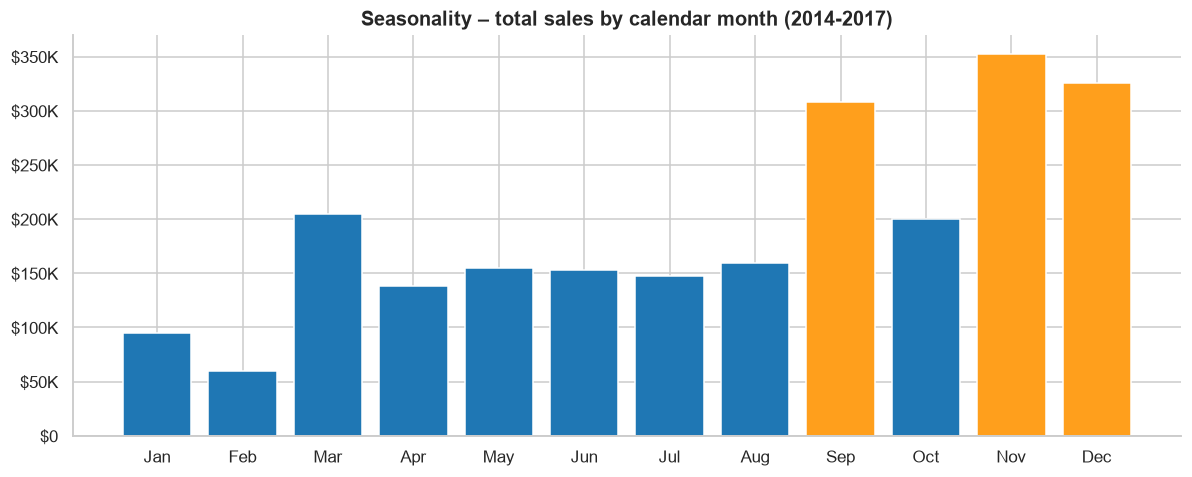

In [11]:
month_names = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
seas = clean.groupby("Order_Month")[["Sales", "Profit"]].sum()
fig, ax = plt.subplots(figsize=(11, 4.5))
colors = [ORANGE if v >= seas.Sales.nlargest(3).min() else BLUE for v in seas.Sales]
ax.bar(month_names, seas.Sales, color=colors); ax.yaxis.set_major_formatter(money)
ax.set_title("Seasonality – total sales by calendar month (2014-2017)")
save("04_seasonality")

### 5.5 Products: category & sub-category

,Sales,Profit,Avg_Discount,Margin_%
Category,,,,
Technology,"836,154.03","145,454.95",0.13,17.40
Office Supplies,"719,047.03","122,490.80",0.16,17.04
Furniture,"741,999.80","18,451.27",0.17,2.49


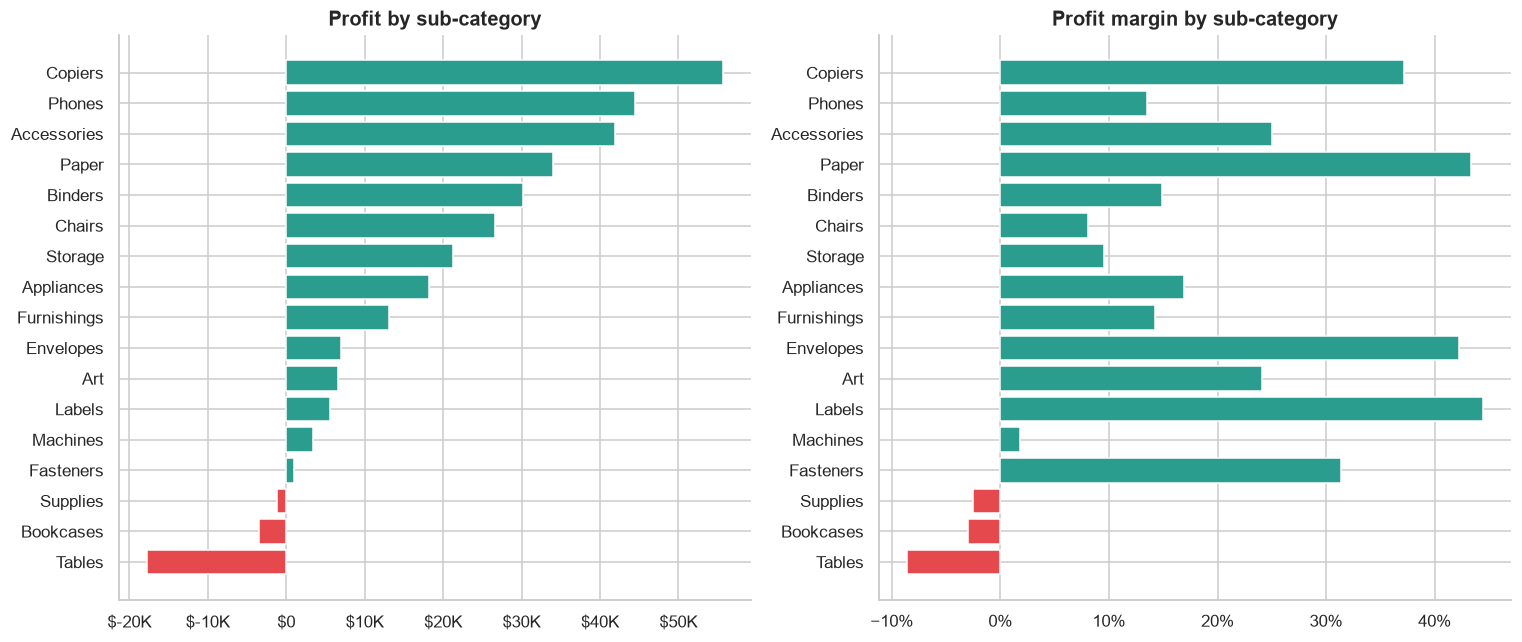

In [12]:
cat = clean.groupby("Category").agg(Sales=("Sales", "sum"), Profit=("Profit", "sum"), Avg_Discount=("Discount", "mean"))
cat["Margin_%"] = cat.Profit / cat.Sales * 100
display(cat.sort_values("Profit", ascending=False).round(2))

sub = clean.groupby(["Category", "Sub_Category"]).agg(Sales=("Sales", "sum"), Profit=("Profit", "sum"), Avg_Discount=("Discount", "mean")).reset_index()
sub["Margin_%"] = sub.Profit / sub.Sales * 100
sub = sub.sort_values("Profit")

fig, ax = plt.subplots(1, 2, figsize=(14, 6))
ax[0].barh(sub.Sub_Category, sub.Profit, color=[GREEN if v >= 0 else RED for v in sub.Profit])
ax[0].xaxis.set_major_formatter(money); ax[0].set_title("Profit by sub-category")
ax[1].barh(sub.Sub_Category, sub["Margin_%"], color=[GREEN if v >= 0 else RED for v in sub["Margin_%"]])
ax[1].xaxis.set_major_formatter(mtick.PercentFormatter()); ax[1].set_title("Profit margin by sub-category")
save("05_subcategory_profit")

### 5.6 Geography

,Sales,Profit,Margin_%
Region,,,
West,"725,457.80","108,418.40",14.90
East,"678,781.20","91,522.80",13.50
South,"391,721.90","46,749.40",11.90
Central,"501,239.90","39,706.40",7.90


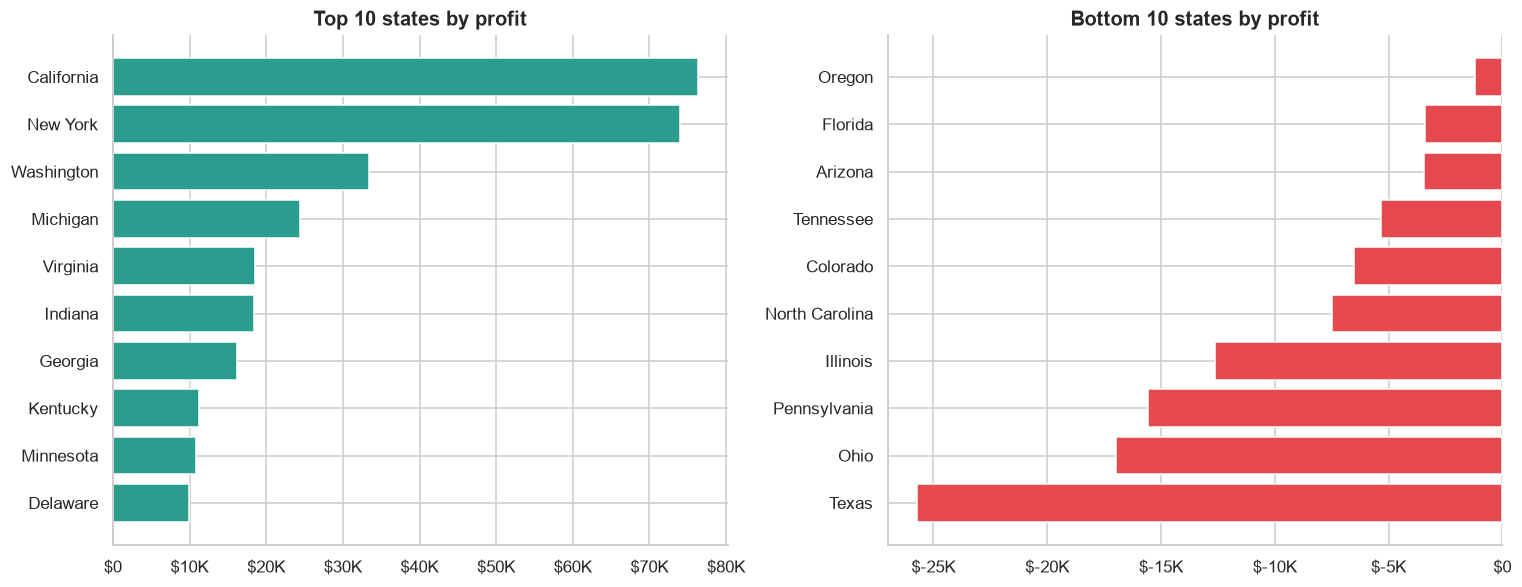

Unprofitable states: 10 of 49


In [13]:
reg = clean.groupby("Region").agg(Sales=("Sales", "sum"), Profit=("Profit", "sum"))
reg["Margin_%"] = reg.Profit / reg.Sales * 100
display(reg.sort_values("Profit", ascending=False).round(1))

state = clean.groupby("State").agg(Sales=("Sales", "sum"), Profit=("Profit", "sum")).sort_values("Profit")
fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))
ax[0].barh(state.Profit.tail(10).index, state.Profit.tail(10), color=GREEN); ax[0].set_title("Top 10 states by profit")
ax[1].barh(state.Profit.head(10).index, state.Profit.head(10), color=RED);  ax[1].set_title("Bottom 10 states by profit")
for a in ax: a.xaxis.set_major_formatter(money)
save("06_state_profit")
print(f"Unprofitable states: {(state.Profit < 0).sum()} of {len(state)}")

### 5.7 Discounts – the key driver of profit

,Lines,Sales,Profit,Loss_Share,Margin_%
Discount_Band,,,,,
No discount,4798,"1,087,908.50","320,987.60",0.00,29.50
1-10%,94,"54,369.40","9,029.20",4.30,16.60
11-20%,3709,"792,152.90","91,756.30",14.00,11.60
21-40%,460,"234,137.90","-35,817.50",90.20,-15.30
41-60%,215,"71,048.20","-28,944.20",100.00,-40.70
61%+,718,"57,584.00","-70,614.40",100.00,-122.60


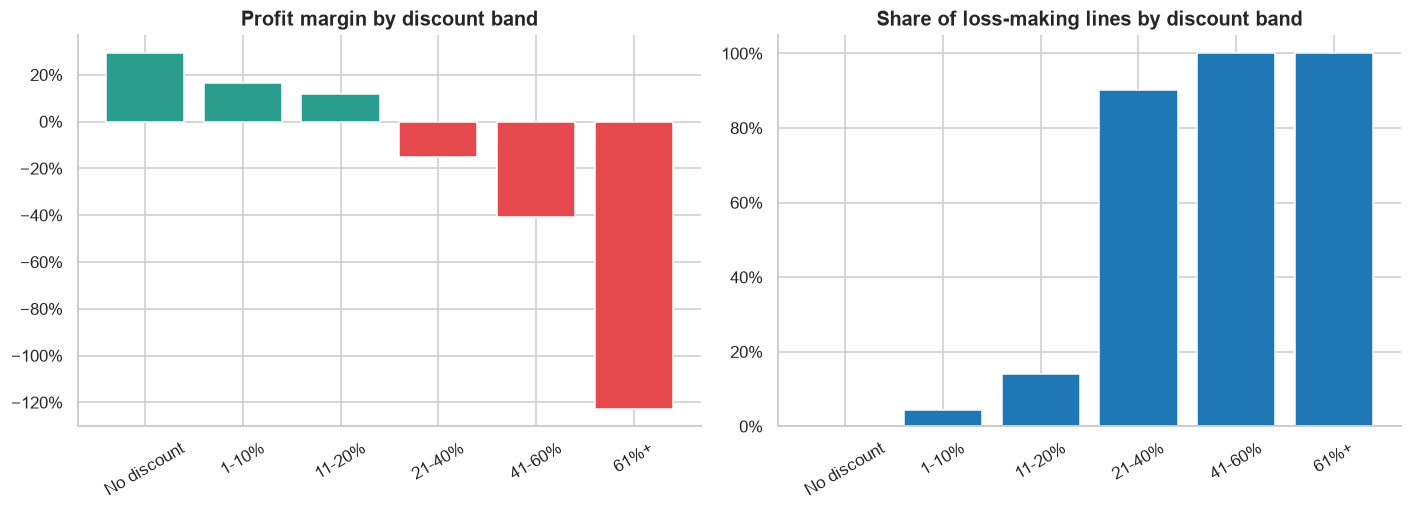

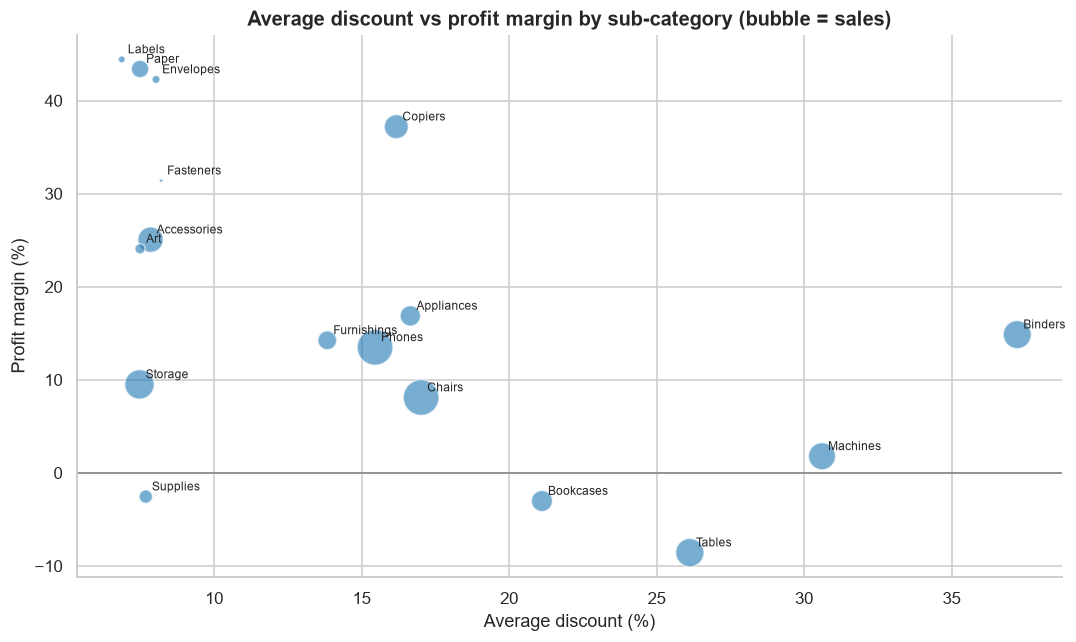

In [14]:
disc = clean.groupby("Discount_Band", observed=True).agg(Lines=("Row_ID", "count"), Sales=("Sales", "sum"),
                                                         Profit=("Profit", "sum"), Loss_Share=("Is_Loss", "mean"))
disc["Margin_%"] = disc.Profit / disc.Sales * 100
disc["Loss_Share"] *= 100
display(disc.round(1))

fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
ax[0].bar(disc.index.astype(str), disc["Margin_%"], color=[GREEN if v >= 0 else RED for v in disc["Margin_%"]])
ax[0].yaxis.set_major_formatter(mtick.PercentFormatter()); ax[0].set_title("Profit margin by discount band")
ax[1].bar(disc.index.astype(str), disc.Loss_Share, color=BLUE)
ax[1].yaxis.set_major_formatter(mtick.PercentFormatter()); ax[1].set_title("Share of loss-making lines by discount band")
for a in ax: a.tick_params(axis="x", rotation=30)
save("07_discount_impact")

sd = clean.groupby("Sub_Category").agg(Avg_Discount=("Discount", "mean"), Sales=("Sales", "sum"), Profit=("Profit", "sum"))
sd["Margin_%"] = sd.Profit / sd.Sales * 100
fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(sd.Avg_Discount * 100, sd["Margin_%"], s=sd.Sales / 600, color=BLUE, alpha=.6, edgecolor="white")
for name, r in sd.iterrows():
    ax.annotate(name, (r.Avg_Discount * 100, r["Margin_%"]), fontsize=8, xytext=(4, 4), textcoords="offset points")
ax.axhline(0, color="grey", lw=1); ax.set_xlabel("Average discount (%)"); ax.set_ylabel("Profit margin (%)")
ax.set_title("Average discount vs profit margin by sub-category (bubble = sales)")
save("08_discount_vs_margin")

### 5.8 Shipping

,Lines,Avg_Ship_Days,Sales,Profit,Margin_%
Ship_Mode,,,,,
First Class,1538,2.18,"351,428.42","48,969.84",13.93
Same Day,543,0.04,"128,363.12","15,891.76",12.38
Second Class,1945,3.24,"459,193.57","57,446.64",12.51
Standard Class,5968,5.01,"1,358,215.74","164,088.79",12.08


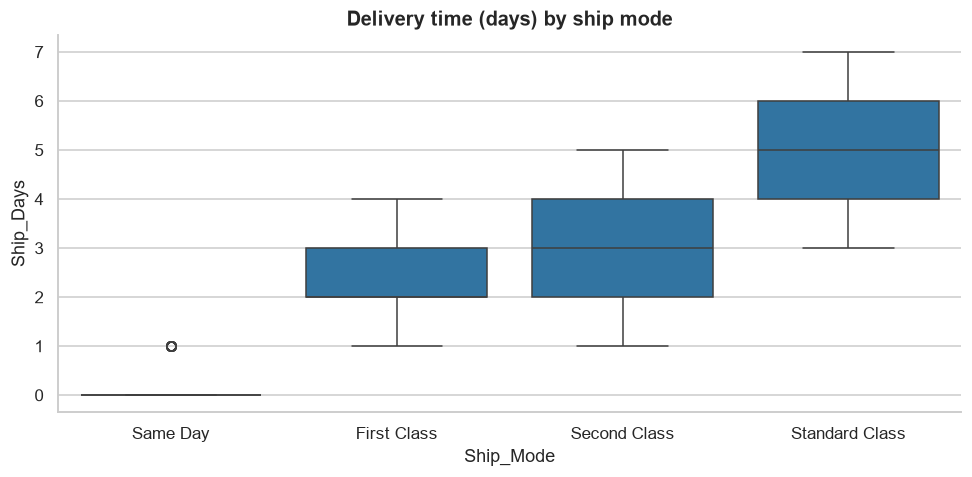

In [15]:
ship = clean.groupby("Ship_Mode").agg(Lines=("Row_ID", "count"), Avg_Ship_Days=("Ship_Days", "mean"),
                                      Sales=("Sales", "sum"), Profit=("Profit", "sum"))
ship["Margin_%"] = ship.Profit / ship.Sales * 100
display(ship.round(2))
order = ["Same Day", "First Class", "Second Class", "Standard Class"]
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.boxplot(data=clean, x="Ship_Mode", y="Ship_Days", order=order, color=BLUE, ax=ax)
ax.set_title("Delivery time (days) by ship mode")
save("09_ship_days")

### 5.9 Correlations

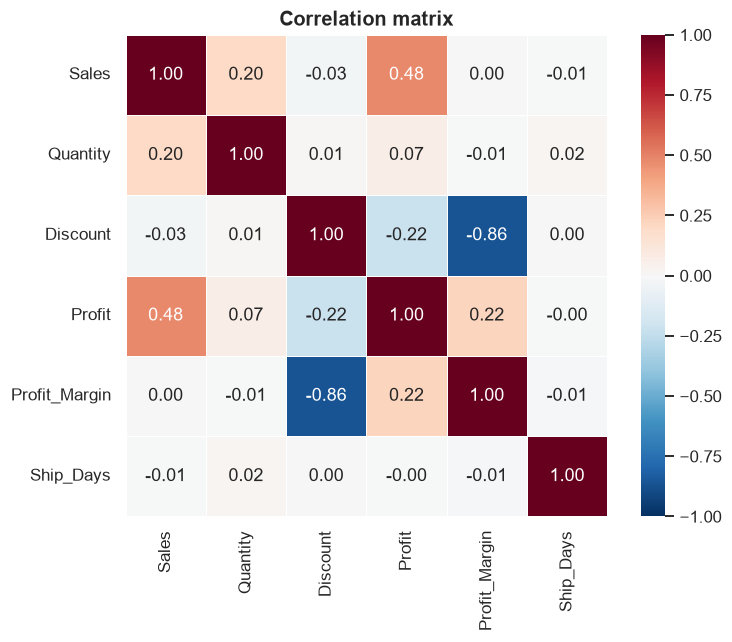

In [16]:
num = ["Sales", "Quantity", "Discount", "Profit", "Profit_Margin", "Ship_Days"]
fig, ax = plt.subplots(figsize=(7.5, 6))
sns.heatmap(clean[num].corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, square=True, linewidths=.5, ax=ax)
ax.set_title("Correlation matrix")
save("10_correlation")

### 5.10 Customers & products

In [17]:
cust = clean.groupby(["Customer_ID", "Customer_Name"]).agg(Orders=("Order_ID", "nunique"), Sales=("Sales", "sum"), Profit=("Profit", "sum")).sort_values("Profit", ascending=False)
print("Top 10 customers by profit"); display(cust.head(10).round(0))
print("Bottom 5 customers by profit"); display(cust.tail(5).round(0))

top20 = cust.Sales.sort_values(ascending=False).head(int(len(cust) * .2)).sum() / cust.Sales.sum()
print(f"Top 20% of customers generate {top20:.0%} of sales; {(cust.Profit < 0).mean():.0%} of customers are unprofitable overall.")

prod = clean.groupby("Product_ID").agg(Product_Name=("Product_Name", "first"), Sales=("Sales", "sum"), Profit=("Profit", "sum"), Qty=("Quantity", "sum"))
print("\nTop 10 products by profit");  display(prod.sort_values("Profit", ascending=False).head(10).round(0))
print("Bottom 10 products by profit"); display(prod.sort_values("Profit").head(10).round(0))

Top 10 customers by profit


,,Orders,Sales,Profit
Customer_ID,Customer_Name,,,
TC-20980,Tamara Chand,5,"19,052.00","8,981.00"
RB-19360,Raymond Buch,6,"15,117.00","6,976.00"
SC-20095,Sanjit Chand,9,"14,142.00","5,757.00"
HL-15040,Hunter Lopez,6,"12,873.00","5,622.00"
AB-10105,Adrian Barton,10,"14,474.00","5,445.00"
TA-21385,Tom Ashbrook,4,"14,596.00","4,704.00"
CM-12385,Christopher Martinez,4,"8,954.00","3,900.00"
KD-16495,Keith Dawkins,12,"8,181.00","3,039.00"
AR-10540,Andy Reiter,6,"6,608.00","2,885.00"


Bottom 5 customers by profit


,,Orders,Sales,Profit
Customer_ID,Customer_Name,,,
HG-14965,Henry Goldwyn,12,"3,248.00","-2,798.00"
SR-20425,Sharelle Roach,5,"3,233.00","-3,334.00"
LF-17185,Luke Foster,7,"3,931.00","-3,584.00"
GT-14635,Grant Thornton,3,"9,351.00","-4,109.00"
CS-12505,Cindy Stewart,6,"5,690.00","-6,626.00"


Top 20% of customers generate 48% of sales; 20% of customers are unprofitable overall.

Top 10 products by profit


,Product_Name,Sales,Profit,Qty
Product_ID,,,,
TEC-CO-10004722,Canon imageCLASS 2200 Advanced Copier,"61,600.00","25,200.00",20
OFF-BI-10003527,Fellowes PB500 Electric Punch Plastic Comb Bin...,"27,453.00","7,753.00",31
TEC-CO-10001449,Hewlett Packard LaserJet 3310 Copier,"18,840.00","6,984.00",38
TEC-CO-10003763,Canon PC1060 Personal Laser Copier,"11,620.00","4,571.00",19
TEC-AC-10002049,Logitech G19 Programmable Gaming Keyboard,"13,757.00","4,425.00",60
TEC-MA-10001127,HP Designjet T520 Inkjet Large Format Printer ...,"18,375.00","4,095.00",12
TEC-MA-10003979,Ativa V4110MDD Micro-Cut Shredder,"7,700.00","3,773.00",11
TEC-MA-10001047,"3D Systems Cube Printer, 2nd Generation, Magenta","14,300.00","3,718.00",11
OFF-BI-10001120,Ibico EPK-21 Electric Binding System,"15,876.00","3,345.00",13


Bottom 10 products by profit


,Product_Name,Sales,Profit,Qty
Product_ID,,,,
TEC-MA-10000418,Cubify CubeX 3D Printer Double Head Print,"11,100.00","-8,880.00",9
TEC-MA-10000822,Lexmark MX611dhe Monochrome Laser Printer,"16,830.00","-4,590.00",18
TEC-MA-10004125,Cubify CubeX 3D Printer Triple Head Print,"8,000.00","-3,840.00",4
FUR-TA-10000198,Chromcraft Bull-Nose Wood Oval Conference Tabl...,"9,918.00","-2,876.00",27
FUR-TA-10001889,Bush Advantage Collection Racetrack Conference...,"9,545.00","-1,934.00",33
OFF-BI-10004995,GBC DocuBind P400 Electric Binding System,"17,965.00","-1,878.00",27
TEC-MA-10002412,Cisco TelePresence System EX90 Videoconferenci...,"22,638.00","-1,811.00",6
OFF-SU-10002881,Martin Yale Chadless Opener Electric Letter Op...,"16,656.00","-1,299.00",22
FUR-TA-10001950,Balt Solid Wood Round Tables,"6,519.00","-1,201.00",19


## 6. Key insights

1. **Healthy growth, thin overall margin.** Sales total \$2.30M with \$286K profit (**12.5%** margin). Sales growth by year: 2015 **-2.8%**, 2016 **+29.5%**, 2017 **+20.4%**; profit grows every year.
2. **Strong seasonality.** The three biggest sales months are **Sep, Nov, Dec** (holiday season plus September) – the natural window for inventory and marketing.
3. **Discounts are the biggest profit killer.** Lines with discounts above 20% run at a **-37.3%** margin vs **21.8%** for the rest, and the Discount–Profit correlation is **-0.22**. 18.7% of all order lines lose money.
4. **Three sub-categories lose money:** Tables (\$-17.7K, average discount 26%), Bookcases (\$-3.5K) and Supplies (\$-1.2K). Furniture is the weakest category by margin (2.5%) while Technology earns the most profit (\$145K).
5. **Regional gap.** West leads on margin (14.9%); Central is the weakest (7.9%). **10 of 49 states are unprofitable**, led by Texas (\$-25.7K).
6. **Customer concentration.** The top 20% of customers generate **48%** of sales, and **20%** of customers are unprofitable overall.

### Recommended next questions for the SQL stage
- Which products / sub-categories should have discounts capped, and what would profit be at a 20% cap?
- Region × category and state-level profitability ranking.
- Year-over-year and month-over-month growth with window functions.
- Customer ranking (RFM-style) and repeat-purchase behaviour.

## 7. Export the clean dataset

In [18]:
out = clean.copy()
out["Discount_Band"] = out["Discount_Band"].astype(str)
for c in ["Order_Date", "Ship_Date"]:
    out[c] = out[c].dt.strftime("%Y-%m-%d")
out.to_csv(CLEAN / "Superstore_clean.csv", index=False, encoding="utf-8")
print(f"Saved {CLEAN / 'Superstore_clean.csv'}  ->  {out.shape[0]:,} rows × {out.shape[1]} columns")
print("Charts saved in:", IMG.resolve())

Saved ..\data\clean\Superstore_clean.csv  ->  9,994 rows × 31 columns
Charts saved in: F:\projects\Superstore-Analysis\images
